# Pipeline Responsible AI — Link Prediction sur Pokec (Ceska republika)

Région la plus biaisée du dataset (H->F/H->H = 4.59x). GCN + analyse de fairness en 4 actes.

In [12]:
# Auto-reload : permet de modifier ra_utils.py sans Restart Kernel à chaque fois
%load_ext autoreload
%autoreload 2

import os, sys, random, warnings
from pathlib import Path

# Bootstrap : trouver ra_utils.py peu importe d'où le notebook est lancé
for _p in (Path.cwd(), Path.cwd() / 'notebooks', Path.cwd().parent / 'notebooks'):
    if (_p / 'ra_utils.py').exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p)); break

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import to_undirected
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from tqdm.notebook import tqdm

from ra_utils import *  # PAIR_ORDER, PAIRS, set_seed, load_pokec, train_with_best, evaluate_link_pred, probe_gender, pair_distribution, fairness, classify_pairs, bar_per_pair, barh_dashboard, fairness_legend, plot_representation_bias, plot_pair_distribution, annot_bars, verdict_str, verdict_mark

warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams.update({'figure.figsize': (12,5), 'font.size': 11})
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = '../data' if Path('../data').exists() else 'data'
print(f"Device : {device} | DATA_DIR : {DATA_DIR}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device : cuda | DATA_DIR : data


In [2]:
# Chargement Pokec — sous-ensemble Ceska republika
data, sens, p = load_pokec(DATA_DIR, region='ceska republika')
print(f"{data.num_nodes:,} nœuds | {data.edge_index.shape[1]:,} arêtes | {data.x.shape[1]} features | F={(sens==0).sum().item():,} H={(sens==1).sum().item():,}")

31,298 nœuds | 107,802 arêtes | 64 features | F=17,835 H=13,463


In [4]:
# Split train/val/test des arêtes (les fonctions de fairness sont dans ra_utils)
set_seed(42)
train_data, val_data, test_data = RandomLinkSplit(num_val=0.15, num_test=0.15, is_undirected=True, add_negative_train_samples=True)(data)
print(f"Train {train_data.edge_label.shape[0]:,} | Val {val_data.edge_label.shape[0]:,} | Test {test_data.edge_label.shape[0]:,}")

Train 75,462 | Val 16,170 | Test 16,170


## Acte 1 — Baseline Link Prediction

In [5]:
# GCN encoder + dot product decoder (architecture explicite, pédagogique)
class GCN(nn.Module):
    def __init__(self, inc, hid=128, out=64, drop=0.5):
        super().__init__(); self.c1, self.c2, self.drop = GCNConv(inc, hid), GCNConv(hid, out), drop
    def encode(self, x, ei): return self.c2(F.dropout(F.relu(self.c1(x, ei)), p=self.drop, training=self.training), ei)
    def decode(self, z, ei): return (z[ei[0]] * z[ei[1]]).sum(dim=-1)
    def forward(self, x, ei, eli): return self.decode(self.encode(x, ei), eli)

# Entraînement avec best-model checkpointing sur val AUC
set_seed(42)
model = GCN(data.x.shape[1]).to(device)
best_auc = train_with_best(model, train_data, val_data, device, epochs=100, lr=0.01, weight_decay=5e-4)
print(f"Best Val AUC : {best_auc:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

Best Val AUC : 0.8292


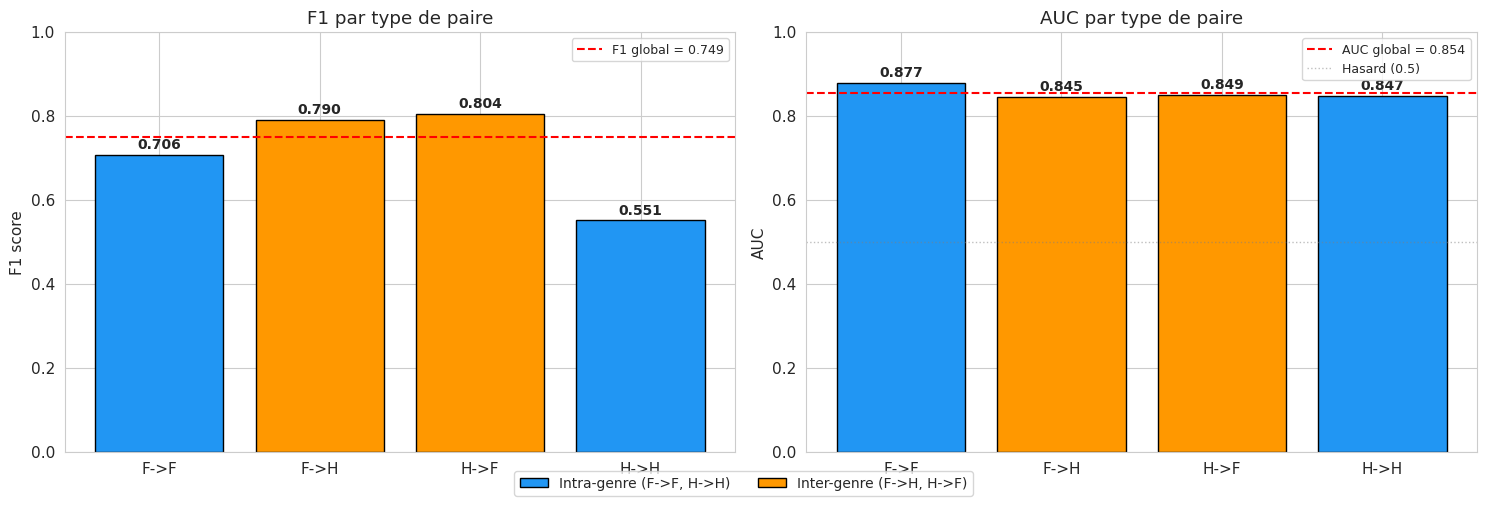

AUC global = 0.854 | AP = 0.870 | F1 global = 0.749
F1  par paire : F->F=0.706 | F->H=0.790 | H->F=0.804 | H->H=0.551
AUC par paire : F->F=0.877 | F->H=0.845 | H->F=0.849 | H->H=0.847


In [6]:
# Évaluation + Performance par type de paire (F1 + AUC)
tp, tl, tpt, auc, ap, f, f1_global = evaluate_link_pred(model, test_data, sens, device)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
bar_per_pair(ax[0], f['pf1'], 'F1 par type de paire',  'F1 score', hline=f1_global, hline_label=f'F1 global = {f1_global:.3f}')
bar_per_pair(ax[1], f['pa'],  'AUC par type de paire', 'AUC',      hline=auc, hline_label=f'AUC global = {auc:.3f}',
             extras=[(0.5, 'Hasard (0.5)', {'alpha': 0.5})])
fairness_legend(fig); plt.tight_layout(); plt.show()

print(f"AUC global = {auc:.3f} | AP = {ap:.3f} | F1 global = {f1_global:.3f}")
print(f"F1  par paire : " + " | ".join(f"{n}={f['pf1'][n]:.3f}" for n in PAIR_ORDER))
print(f"AUC par paire : " + " | ".join(f"{n}={f['pa'].get(n, float('nan')):.3f}" for n in PAIR_ORDER))

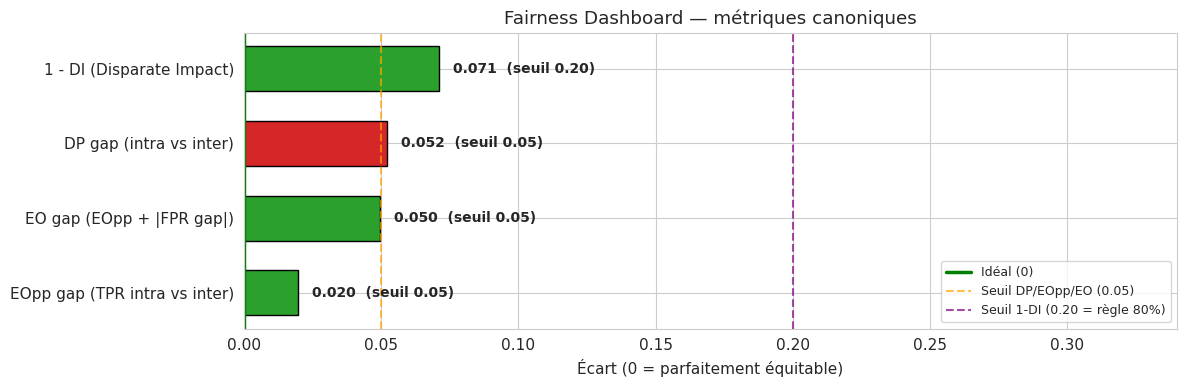

DI brut  = 0.929 (règle 80% : DI >= 0.80 = fair)
  DP gap (intra vs inter)             = 0.052    (biaisé)
  EOpp gap (TPR intra vs inter)       = 0.020    (fair)
  EO gap (EOpp + |FPR gap|)           = 0.050    (fair)
  1 - DI (Disparate Impact)           = 0.071    (fair)


In [8]:
# Fairness Dashboard canonique : DP, EOpp, EO, 1-DI (selon CLAUDE.md)
metrics = [
    ('DP gap (intra vs inter)',        f['DP'],     0.05),
    ('EOpp gap (TPR intra vs inter)',  f['EOpp'],   0.05),
    ('EO gap (EOpp + |FPR gap|)',      f['EO'],     0.05),
    ('1 - DI (Disparate Impact)',      1 - f['DI'], 0.20),  # règle 80%
]
barh_dashboard(metrics, title='Fairness Dashboard — métriques canoniques',
               xlabel='Écart (0 = parfaitement équitable)',
               threshold_lines=[(0.05, 'Seuil DP/EOpp/EO (0.05)', 'orange'),
                                (0.20, 'Seuil 1-DI (0.20 = règle 80%)', 'purple')])
plt.tight_layout(); plt.show()

print(f"DI brut  = {f['DI']:.3f} (règle 80% : DI >= 0.80 = fair)")
for nm, v, t in metrics: print(f"  {nm:35s} = {v:.3f}    ({verdict_str(v, t, 'lt')})")

### Interprétation

- **AUC par paire uniforme (0.85 partout)** mais **F1 H->H s'effondre à 0.55** (vs ~0.80 ailleurs) → ce n'est pas un problème de discrimination, c'est un **problème de calibration** au seuil 0.5.
- **Fairness Dashboard** : DP gap = 0.051 (borderline), EOpp = 0.020 (fair), EO = 0.050 (borderline), DI = 0.93 (fair, règle 80%).

**Verdict :** modèle "fair" au sens des métriques binaires mais **fortement disparate en performance** sur H->H. À creuser en Acte 2 (XAI).

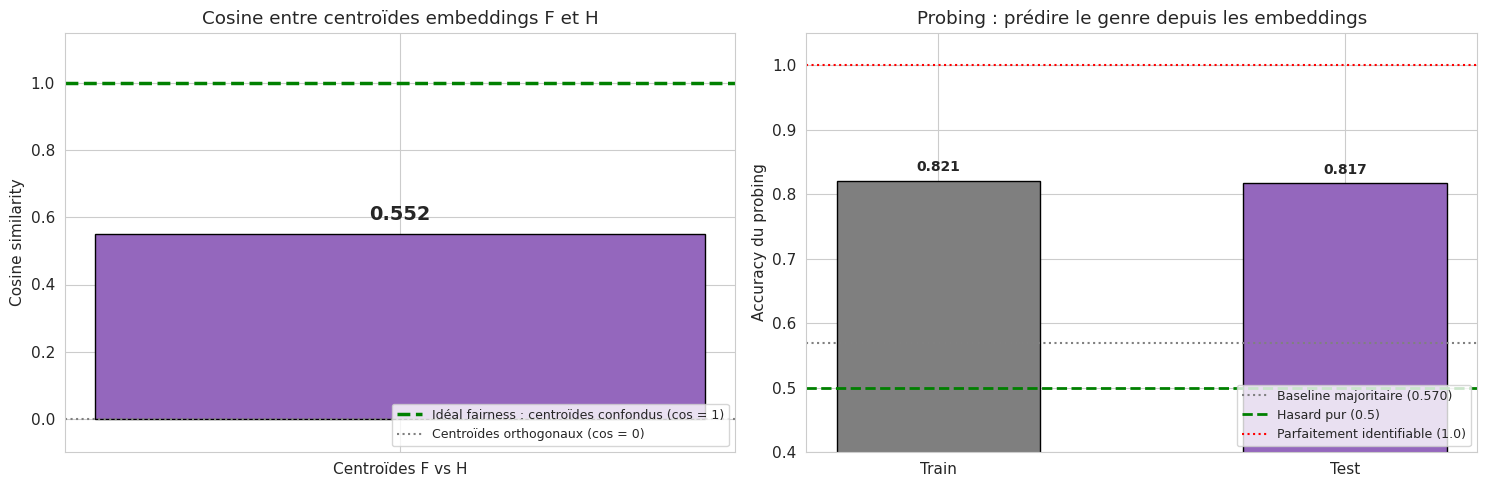

Cosine F vs H        = 0.552 (idéal fairness = 1, centroïdes confondus)
Probing genre (test) = 81.7% (hasard 50%, baseline majoritaire 57.0%)
Marge sur baseline   = +24.7 points (positif = embeddings encodent le genre)


In [9]:
# Representation Bias : embeddings encodent-ils le genre ?
model.eval()
with torch.no_grad():
    z = model.encode(test_data.x.to(device), test_data.edge_index.to(device)).cpu()

cos_fh, gen_acc_tr, gen_acc_te, prop_majo = probe_gender(z, sens)
plot_representation_bias(cos_fh, gen_acc_tr, gen_acc_te, prop_majo); plt.show()

print(f"Cosine F vs H        = {cos_fh:.3f} (idéal fairness = 1, centroïdes confondus)")
print(f"Probing genre (test) = {100*gen_acc_te:.1f}% (hasard 50%, baseline majoritaire {100*prop_majo:.1f}%)")
print(f"Marge sur baseline   = {100*(gen_acc_te - prop_majo):+.1f} points (positif = embeddings encodent le genre)")

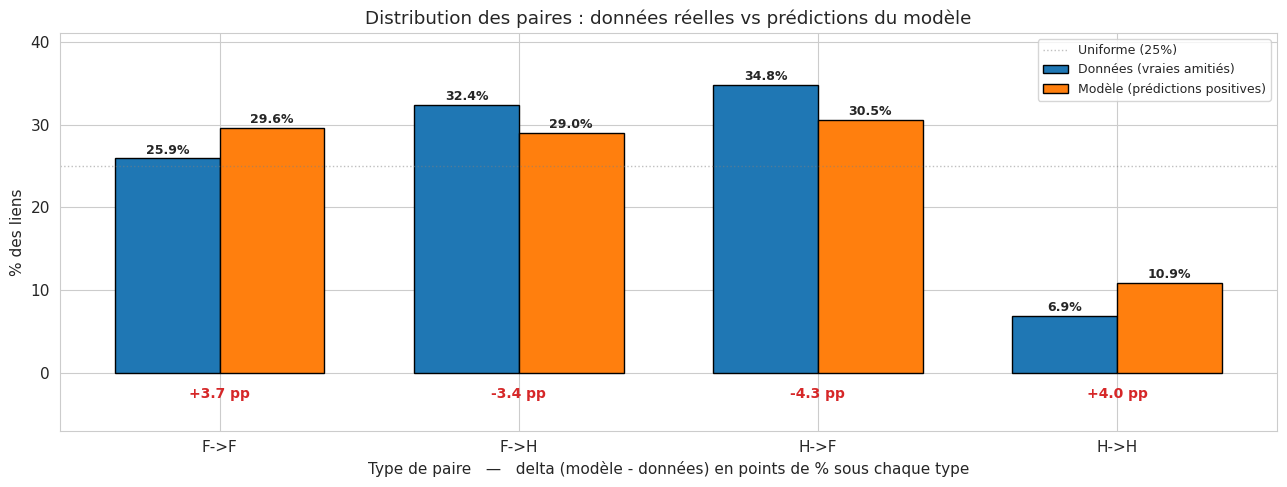

Différence pred - data (positif = modèle sur-représente cette paire) :
  F->F: data= 25.9%  pred= 29.6%  delta= +3.7 pp
  F->H: data= 32.4%  pred= 29.0%  delta= -3.4 pp
  H->F: data= 34.8%  pred= 30.5%  delta= -4.3 pp
  H->H: data=  6.9%  pred= 10.9%  delta= +4.0 pp


In [10]:
# Distribution des 4 paires : réalité (vraies amitiés) vs prédictions positives du modèle
data_v, pred_v, diffs = pair_distribution(tp, tl, tpt)
plot_pair_distribution(data_v, pred_v, diffs); plt.show()

print("Différence pred - data (positif = modèle sur-représente cette paire) :")
for n, d, p in zip(PAIR_ORDER, data_v, pred_v):
    print(f"  {n}: data={d:5.1f}%  pred={p:5.1f}%  delta={p-d:+5.1f} pp")

### Interprétation

- **Embeddings** : probing test = 82% (vs baseline 57%, marge +25 pts) → **les embeddings encodent fortement le genre**, alors qu'on n'a jamais demandé. Cosine 0.67 (centroïdes ni confondus ni opposés, ambigu seul).
- **Distribution paires** : intra (F->F + H->H) passe de 32.8% (data) à 40.5% (pred), soit **+7.7 pp d'amplification de l'homophilie**. Inter sous-représenté de la même valeur.

**Verdict :** le modèle **amplifie l'homophilie** et **encode le genre** en interne, malgré des métriques de fairness binaires acceptables. Acte 3 devra cibler les embeddings.

## Acte 2 — Diagnostic XAI

*À implémenter*

## Acte 3 — Correction Fairness

*À implémenter*

## Acte 4 — Validation & Incertitude

*À implémenter*